# Unidad 4 · Sesión 3, parte 1 — Del grafo al paso de mensajes

Cuaderno de ilustración de la primera parte de la clase (Hamilton, apertura del cap. 5 y secs. 5.1–5.2): el grafo $K_4-e$ y sus permutaciones, la fórmula de Euler, invariancia y equivarianza, la GNN básica y la normalización de la GCN. La segunda parte está en `U4_S3_MessagePassing_parte2.ipynb`.

Lo ejecutamos juntos celda por celda. Hay tres **ejercicios** para resolver en clase; su solución está en una celda oculta justo debajo (en Colab, haga clic en *Mostrar código*).

En Colab, PyTorch ya viene instalado; falta PyTorch Geometric (PyG), que usamos en la sección 6.

In [52]:
!pip install -q torch_geometric

In [53]:
# Importaciones para manejo numérico y generación de gráficos
import numpy as np
import matplotlib.pyplot as plt

# Importaciones para permutaciones, teoría de grafos y aprendizaje profundo
import itertools
import networkx as nx
import torch

# Herramientas para la visualización y formateo de texto en Jupyter/Colab
from IPython.display import display, Markdown
from tabulate import tabulate

def dMarkdown(text):
    """Muestra texto en formato Markdown en el notebook."""
    display(Markdown(text))

def dM_table(datos_tabla, headers):
    """Genera y muestra una tabla formateada en Markdown usando tabulate."""
    tabla_md = tabulate(
        datos_tabla,
        headers=headers,
        tablefmt="pipe"
    )
    dMarkdown(tabla_md)

Una función para dibujar todos los grafos con el mismo estilo:

In [54]:
def dibujar(G, pos, ax, titulo=""):
    # Dibuja el grafo usando NetworkX con las especificaciones visuales indicadas
    nx.draw_networkx(G, pos, ax=ax,
                     node_color="#d9f2e1", # Color de relleno de los nodos (verde claro)
                     edgecolors="#009b3a", # Color del borde de los nodos (verde oscuro)
                     edge_color="0.4",     # Color de las aristas (gris)
                     node_size=500,        # Tamaño de los nodos
                     width=2,              # Ancho de las aristas
                     )
    ax.set_title(titulo)   # Establece el título del panel
    ax.margins(0.2)        # Añade un margen para evitar que los nodos queden cortados
    ax.set_aspect("equal") # Mantiene la relación de aspecto cuadrada
    ax.axis("off")         # Oculta los ejes de la gráfica

## 1. Un grafo es quién está unido con quién

Usamos como ejemplo $K_4-e$: el grafo completo de cuatro nodos al que le falta una arista. Lo damos con su **lista de adyacencia**, que dice, para cada nodo, quiénes son sus vecinos. En la lista A los vecinos de cada nodo están escritos en el orden en que se encuentran al girar alrededor de él en sentido antihorario en el dibujo de abajo; ese orden lo usaremos en la sección 3.

In [55]:
# Definición de la lista de adyacencia del grafo K_4-e
lista_A = {0: [1, 3], 1: [0, 2, 3], 2: [1, 3], 3: [0, 1, 2]}

# Inicialización de un grafo no dirigido con NetworkX
G = nx.Graph()
# Adición de los nodos numerados del 0 al 3
G.add_nodes_from(range(4))
# Adición de las aristas recorriendo la lista de adyacencia
G.add_edges_from(
    (u, v)
    for u in lista_A
    for v in lista_A[u]
    )

# Visualización de las aristas ordenadas en formato Markdown y texto plano
dMarkdown("**Aristas:**")
print(sorted(G.edges()))

# Visualización de los grados de cada nodo en formato Markdown y texto plano
dMarkdown("**Grados:**")
print(dict(G.degree()))

**Aristas:**

[(0, 1), (0, 3), (1, 2), (1, 3), (2, 3)]


**Grados:**

{0: 2, 1: 3, 2: 2, 3: 3}


Para dibujarlo se recorre la lista: se toma un nodo, se traza la arista hacia cada vecino con el que todavía no esté unido, y se sigue con el nodo siguiente hasta agotar las aristas. Cada panel añade una arista.

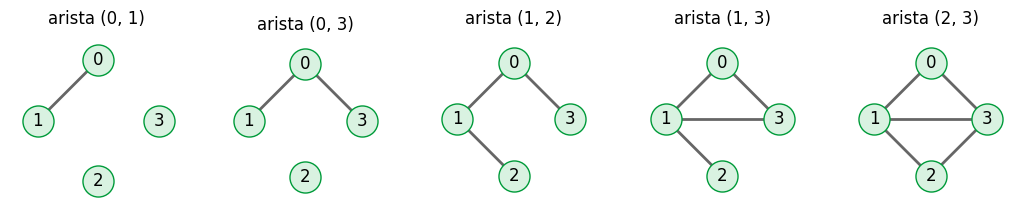

In [56]:
# Coordenadas para posicionar cada nodo en el plano al dibujarlos
pos_A = {0: (0, 1), 1: (-1, 0), 3: (1, 0), 2: (0, -1)}

# Determina el orden de las aristas sin duplicar (evitando u-v y v-u)
orden = []
for u in lista_A:
    for v in lista_A[u]:
        if (v, u) not in orden:
            orden.append((u, v))

# Crea subgráficos horizontales para ver la construcción del grafo paso a paso
fig, axs = plt.subplots(1, len(orden), figsize=(13, 2.8))
for k, ax in enumerate(axs):
    # Crea un subgrafo temporal agregando las aristas de forma incremental
    H = nx.Graph(orden[:k + 1])
    # Asegura que todos los nodos estén presentes, incluso los que aún no tienen aristas
    H.add_nodes_from(G)
    # Dibuja el estado del grafo en esta iteración
    dibujar(H, pos_A, ax, f"arista {orden[k]}")
plt.show()

## 2. Renombrar los nodos no cambia el grafo

Una permutación $\sigma$ cambia el nombre de los nodos: el nodo $i$ pasa a llamarse $\sigma(i)$. En la matriz de adyacencia eso es
$$A' = P A P^\top,\qquad P_{\sigma(i),\,i}=1 ,$$
y los atributos de los nodos se reordenan igual, $X' = PX$.

In [57]:
def matriz_P(sigma):
    # P[sigma[i], i] = 1: el nodo i pasa a llamarse sigma[i]
    n = len(sigma)                     # Obtiene la cantidad de nodos (dimensión de la matriz)
    P = np.zeros((n, n), dtype=int)    # Inicializa una matriz cuadrada de ceros de tamaño n x n
    P[sigma, range(n)] = 1             # Coloca un 1 en cada columna i en la fila correspondiente a sigma[i]
    return P                           # Devuelve la matriz de permutación resultante

El ejemplo de las diapositivas: intercambiar los nodos 2 y 3. La matriz cambia, pero el grafo no.

In [58]:
# Convierte el grafo G a su representación de matriz de adyacencia de NumPy
A_A = nx.to_numpy_array(G, nodelist=range(4), dtype=int)

# Define la permutación que intercambia las etiquetas de los nodos 2 y 3
sigma23 = [0, 1, 3, 2]
# Genera la matriz de permutación correspondiente
P23 = matriz_P(sigma23)
# Aplica la permutación de manera simétrica: P * A * P^T
A_B = P23@A_A@P23.T

# Imprime los resultados utilizando títulos grandes con dMarkdown
dMarkdown("**Matriz Original** ($A_A$):")
print(A_A)

dMarkdown("**Matriz Permutada** ($A_B = P A_A P^\top$):")
print(A_B)

# Comprueba mediante NetworkX si las dos matrices representan estructuralmente el mismo grafo
dMarkdown(f"**¿Representan el mismo grafo?:** `{nx.is_isomorphic(nx.from_numpy_array(A_A), nx.from_numpy_array(A_B))}`")

**Matriz Original** ($A_A$):

[[0 1 0 1]
 [1 0 1 1]
 [0 1 0 1]
 [1 1 1 0]]


**Matriz Permutada** ($A_B = P A_A P^	op$):

[[0 1 1 0]
 [1 0 1 1]
 [1 1 0 1]
 [0 1 1 0]]


**¿Representan el mismo grafo?:** `True`

Con las $4! = 24$ permutaciones, ¿cuántas matrices distintas aparecen? Las permutaciones que dejan la matriz igual son los **automorfismos** del grafo; el número de matrices distintas es $n!/|\mathrm{Aut}|$.

In [59]:
# Diccionario para almacenar las matrices de adyacencia únicas (usando sus bytes como clave)
distintas = {}
# Contador para identificar cuántas permutaciones dejan la matriz de adyacencia idéntica
automorfismos = 0

# Recorre todas las 24 (4!) permutaciones posibles de los nodos
for sigma in itertools.permutations(range(4)):
    # Obtiene la matriz de permutación para la permutación actual
    P = matriz_P(list(sigma))
    # Aplica la permutación de forma simétrica a la matriz de adyacencia original
    Ap = P@A_A@P.T
    # Almacena la matriz resultante en el diccionario (evitando duplicados gracias a las claves únicas)
    distintas.setdefault(Ap.tobytes(), Ap)
    # Incrementa el contador si la matriz permutada es idéntica a la original (A_A)
    automorfismos += np.array_equal(Ap, A_A)

# Convierte las matrices únicas almacenadas a una lista
matrices = list(distintas.values())

# Imprime el conteo de matrices únicas, el número de automorfismos y la relación matemática usando dMarkdown con formato LaTeX corregido
dMarkdown(f"**Matrices distintas:** `{len(matrices)}`")
dMarkdown(f"**$\\text{{|Aut|}}$ (Automorfismos):** `{automorfismos}`")
dMarkdown(f"**Relación:** $\\frac{{24}}{{{automorfismos}}} = {24 // automorfismos}$")

**Matrices distintas:** `6`

**$\text{|Aut|}$ (Automorfismos):** `4`

**Relación:** $\frac{24}{4} = 6$

Las seis matrices dibujadas con los nodos fijos en las esquinas (0 arriba a la izquierda, 1 arriba a la derecha, 2 abajo a la derecha, 3 abajo a la izquierda). En los seis dibujos hay dos nodos de grado 2, dos de grado 3 y una sola arista que falta: es el mismo grafo con los nombres en otro lugar. El dibujo tiene un cruce cuando están las dos diagonales 0–2 y 1–3.

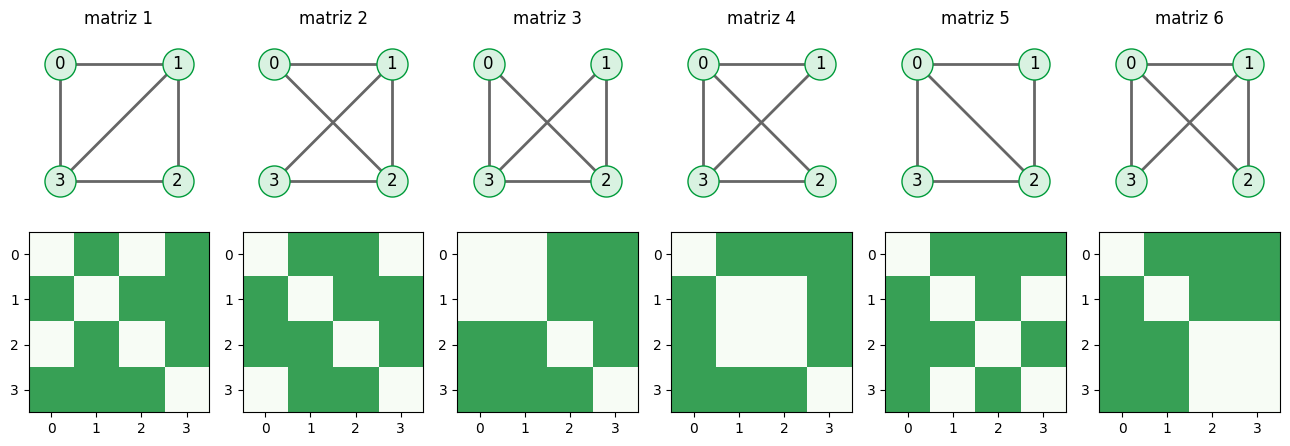

In [60]:
# Coordenadas fijas para colocar los nodos en las esquinas de un cuadrado unitario
pos_esq = {0: (0, 1), 1: (1, 1), 2: (1, 0), 3: (0, 0)}

# Crea una cuadrícula de figuras de 2 filas y 6 columnas (una columna por cada matriz distinta)
fig, axs = plt.subplots(2, 6, figsize=(13, 4.6))

# Recorre cada una de las 6 matrices de adyacencia únicas obtenidas
for k, Ap in enumerate(matrices):
    # Fila 0: Dibuja la estructura del grafo correspondiente a la matriz permutada
    dibujar(nx.from_numpy_array(Ap), pos_esq, axs[0, k], f"matriz {k + 1}")

    # Fila 1: Muestra la representación visual de la matriz de adyacencia usando un mapa de calor
    axs[1, k].imshow(Ap, cmap="Greens", vmin=0, vmax=1.5)
    # Configura los ticks o marcas de los ejes X e Y para los 4 nodos (índices 0 a 3)
    axs[1, k].set_xticks(range(4))
    axs[1, k].set_yticks(range(4))

# Ajusta automáticamente la disposición de los subgráficos para evitar solapamientos
plt.tight_layout()
# Muestra los gráficos resultantes
plt.show()

## 3. El dibujo no es el grafo: caras, fórmula de Euler y género

Si en la lista de cada nodo los vecinos están en el orden en que se encuentran al girar alrededor de él (sentido antihorario), la lista fija una **inmersión**: una manera de dibujar el grafo sobre una superficie sin cruces. Las **caras** se recorren así: se llega al nodo $v$ desde $u$ y se sale hacia el vecino que sigue a $u$ en la lista de $v$ (volviendo al principio de la lista si $u$ es el último). Cada arista se recorre una vez en cada sentido.

Con el número de caras $F$, la fórmula de Euler (válida cuando cada cara es un disco)
$$V - L + F = 2 - 2g$$
da el **género** $g$ de la superficie: $g=0$ es la esfera o el plano, $g=1$ el toro.

In [61]:
def caras(lista):
    # Crea un diccionario de transiciones: para cada nodo 'v', define cuál es el siguiente vecino en sentido antihorario
    siguiente = {v: {w: vec[(i + 1) % len(vec)] for i, w in enumerate(vec)}
                 for v, vec in lista.items()}

    # Lista con todas las aristas dirigidas (cada enlace bidireccional se trata como dos aristas dirigidas distintas)
    libres = [(u, v) for u in lista for v in lista[u]]     # cada arista en los dos sentidos
    resultado = []

    # Mientras queden aristas por recorrer, reconstruye las caras del grafo
    while libres:
        u, v = libres[0]
        cara = []
        # Sigue el camino cerrado hasta regresar a una arista ya visitada en esta cara
        while (u, v) in libres:
            libres.remove((u, v))
            cara.append(u)
            # Al llegar al nodo v desde u, determina el siguiente paso en base al orden de vecindad
            u, v = v, siguiente[v][u]                      # al llegar a v, salir por el siguiente
        resultado.append(cara)
    return resultado


def genero(lista):
    # Calcula el número de vértices (V), aristas (L), caras (F) y el género (g) del grafo
    V = len(lista)
    L = sum(len(vec) for vec in lista.values()) // 2
    F = len(caras(lista))
    # Aplica la relación de Euler generalizada para superficies: V - L + F = 2 - 2g
    return V, L, F, (2 - V + L - F) // 2

La lista A, que leímos del dibujo plano, y la lista B, que es la lista de $A_B$ con los vecinos en orden creciente:

In [62]:
# Lista de adyacencia B: representa el mismo grafo pero con los vecinos ordenados de forma diferente (sentido horario / orden creciente)
lista_B = {0: [1, 2], 1: [0, 2, 3], 2: [0, 1, 3], 3: [1, 2]}

# Evalúa las propiedades topológicas de ambas representaciones (A y B)
for nombre, lista in [("A", lista_A), ("B", lista_B)]:
    # Obtiene los valores de Vértices, Aristas, Caras y el Género usando la fórmula de Euler
    V, L, F, g = genero(lista)
    # Muestra las caras encontradas para cada representación de lista
    print(f"lista {nombre}: caras {caras(lista)}")
    # Imprime los resultados de la relación de Euler y el género resultante (g=0 plano, g=1 toro)
    print(f"         V={V}, L={L}, F={F}  ->  g = {g}")

lista A: caras [[0, 1, 2, 3], [0, 3, 1], [1, 3, 2]]
         V=4, L=5, F=3  ->  g = 0
lista B: caras [[0, 1, 2, 3, 1, 0, 2, 1, 3, 2]]
         V=4, L=5, F=1  ->  g = 1


La lista A tiene tres caras (dos triángulos y la cara exterior): el plano. La lista B tiene una sola cara: Euler da $g=1$, el toro. Aquí está el dibujo sin cruces de la lista B en el toro, representado como un cuadrado cuyos lados opuestos están identificados: una arista que sale por un lado entra por el lado opuesto.

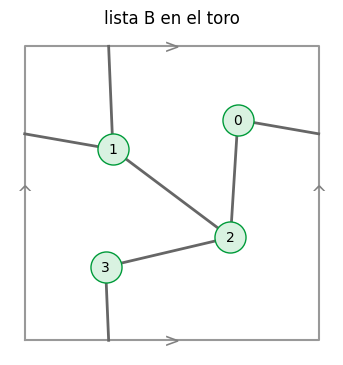

In [63]:
# Definición de los segmentos de línea que conectan los nodos en el toro (algunos cruzan los bordes)
segmentos = [((1.2, 2.6), (2.8, 1.4)),                              # Conexión directa entre nodos 1 y 2
             ((1.2, 2.6), (0, 2.809)), ((4, 2.809), (2.9, 3.0)),    # Conexión 1-0 que cruza por el lado izquierdo hacia el derecho
             ((2.8, 1.4), (2.9, 3.0)),                              # Conexión directa entre nodos 2 y 0
             ((1.2, 2.6), (1.142, 4)), ((1.142, 0), (1.1, 1.0)),    # Conexión 1-3 que cruza por el borde superior hacia el inferior
             ((2.8, 1.4), (1.1, 1.0))]                              # Conexión directa entre nodos 2 y 3

# Coordenadas específicas en el plano 2D para colocar cada uno de los 4 nodos en el gráfico del toro
nodos_toro = {0: (2.9, 3.0), 1: (1.2, 2.6), 2: (2.8, 1.4), 3: (1.1, 1.0)}

# Inicializa la figura de visualización
fig, ax = plt.subplots(figsize=(4.2, 4.2))
# Dibuja el marco exterior que representa la frontera de la porción del toro (cuadrado unitario)
ax.plot([0, 4, 4, 0, 0], [0, 0, 4, 4, 0], color="0.6")

# Dibuja flechas en los bordes para ilustrar que los lados opuestos están identificados (unidos)
for x, y, s in [(2, 0, ">"), (2, 4, ">"), (0, 2, "^"), (4, 2, "^")]:
    ax.text(x, y, s, ha="center", va="center", color="0.5", fontsize=14)

# Dibuja cada uno de los segmentos de arista definidos anteriormente
for (x1, y1), (x2, y2) in segmentos:
    ax.plot([x1, x2], [y1, y2], color="0.4", lw=2)

# Dibuja y etiqueta los nodos sobre el lienzo
for v, (x, y) in nodos_toro.items():
    ax.scatter(x, y, s=500, color="#d9f2e1", edgecolors="#009b3a", zorder=3)
    ax.text(x, y, v, ha="center", va="center", zorder=4)

# Ajusta el diseño final del gráfico del toro
ax.set_title("lista B en el toro")
ax.set_aspect("equal")
ax.axis("off")
plt.show()

Las dos listas describen el mismo grafo ($A_B = P A_A P^\top$), pero ordenadas fijan superficies distintas. Que la lista B viva en el toro es una propiedad de esa lista ordenada, no del grafo: el **género de un grafo** es el mínimo sobre todas sus inmersiones, y $K_4-e$ es plano.



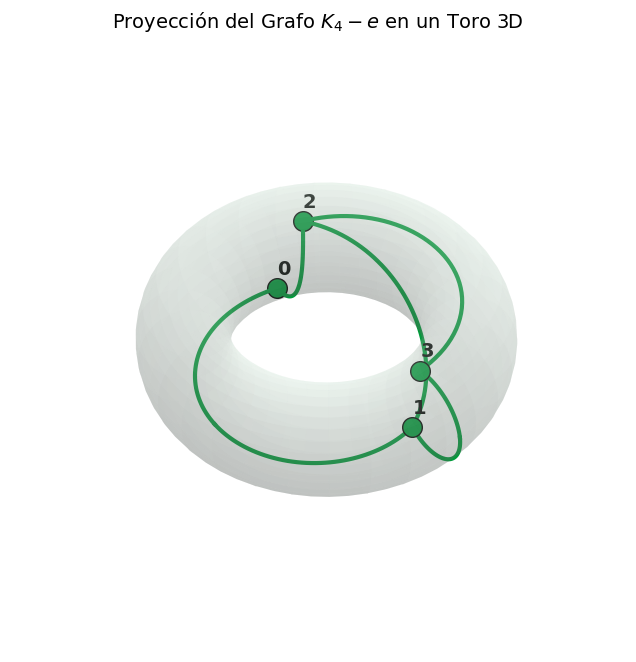

In [64]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Parámetros del toro (Radio mayor R, radio menor r)
R, r = 3, 1

# Función para mapear coordenadas del cuadrado [0, 4]x[0, 4] a la superficie del toro 3D
def mapear_toro(x, y):
    # Convierte las coordenadas a ángulos u, v en [0, 2π]
    u = (x / 4) * 2 * np.pi
    v = (y / 4) * 2 * np.pi

    # Ecuaciones paramétricas del toro
    X = (R + r * np.cos(v)) * np.cos(u)
    Y = (R + r * np.cos(v)) * np.sin(u)
    Z = r * np.sin(v)
    return X, Y, Z

# 1. Dibuja la superficie del toro
u = np.linspace(0, 2 * np.pi, 60)
v = np.linspace(0, 2 * np.pi, 60)
U, V = np.meshgrid(u, v)
X = (R + r * np.cos(V)) * np.cos(U)
Y = (R + r * np.cos(V)) * np.sin(U)
Z = r * np.sin(V)
# Grafica la superficie con transparencia
ax.plot_surface(X, Y, Z, alpha=0.2, color="#d9f2e1", edgecolor='none')

# 2. Dibuja las aristas (segmentos) proyectados en el toro
# Interpolamos puntos a lo largo de cada segmento para que sigan la curvatura
for (x1, y1), (x2, y2) in segmentos:
    t = np.linspace(0, 1, 50)
    x_interp = x1 + t * (x2 - x1)
    y_interp = y1 + t * (y2 - y1)
    X_seg, Y_seg, Z_seg = mapear_toro(x_interp, y_interp)
    ax.plot(X_seg, Y_seg, Z_seg, color="#009b3a", lw=3, zorder=4)

# 3. Dibuja los nodos
for nodo, (x, y) in nodos_toro.items():
    X_n, Y_n, Z_n = mapear_toro(x, y)
    ax.scatter(X_n, Y_n, Z_n, color="#009b3a", s=200, edgecolor="black", zorder=5)
    ax.text(X_n, Y_n, Z_n + 0.3, str(nodo), color='black', fontsize=14, weight='bold', zorder=6)

# Ajustes visuales de la vista 3D
ax.set_title("Proyección del Grafo $K_4-e$ en un Toro 3D", fontsize=14)
ax.set_box_aspect([1, 1, r/R]) # Relación de aspecto
ax.axis("off")

# Ángulo de visión
ax.view_init(elev=45, azim=60)
plt.show()

### Ejercicio 1
Escriba las listas de adyacencia de las seis matrices de la sección 2, con los vecinos en orden creciente. Recorra las caras de cada una con `caras` y compruebe que dos dan el plano ($F=3$) y cuatro el toro ($F=1$). ¿Qué tienen en común los dibujos en las esquinas de las dos listas planas?

In [65]:
# Lista para almacenar los resultados a mostrar en la tabla
datos_tabla = []

# Recorre cada una de las 6 matrices de adyacencia únicas identificadas anteriormente
for k, Ap in enumerate(matrices, start=1):
    # Reconstruye la lista de adyacencia para la matriz actual (obteniendo los índices donde hay conexiones '1')
    lista = {v: [int(w) for w in np.flatnonzero(Ap[v])] for v in range(4)}

    # Determina el número de vértices, aristas, caras y el género de la superficie
    V, L, F, g = genero(lista)

    # Añade los datos recolectados a la tabla
    datos_tabla.append([f"Matriz {k}", str(lista), F, g])

# Cabeceras de la tabla
cabeceras = ["Matriz", "Lista de Adyacencia", "Caras (F)", "Género (g)"]

# Muestra la tabla formateada con la función utilitaria dM_table
dM_table(datos_tabla, cabeceras)

| Matriz   | Lista de Adyacencia                                |   Caras (F) |   Género (g) |
|:---------|:---------------------------------------------------|------------:|-------------:|
| Matriz 1 | {0: [1, 3], 1: [0, 2, 3], 2: [1, 3], 3: [0, 1, 2]} |           3 |            0 |
| Matriz 2 | {0: [1, 2], 1: [0, 2, 3], 2: [0, 1, 3], 3: [1, 2]} |           1 |            1 |
| Matriz 3 | {0: [2, 3], 1: [2, 3], 2: [0, 1, 3], 3: [0, 1, 2]} |           1 |            1 |
| Matriz 4 | {0: [1, 2, 3], 1: [0, 3], 2: [0, 3], 3: [0, 1, 2]} |           1 |            1 |
| Matriz 5 | {0: [1, 2, 3], 1: [0, 2], 2: [0, 1, 3], 3: [0, 2]} |           3 |            0 |
| Matriz 6 | {0: [1, 2, 3], 1: [0, 2, 3], 2: [0, 1], 3: [0, 1]} |           1 |            1 |

Explicación del resultado:
- Planas (g=0): Las matrices cuya representación en las esquinas no tiene cruces de aristas.
  Estas corresponden a los casos donde falta una de las diagonales principales (0-2 o 1-3).
- Toro (g=1): Las otras cuatro combinaciones contienen cruces de diagonales, lo que fuerza
  a que el grafo se proyecte con una única gran cara sobre una superficie toroidal.

## 4. Fórmula de Euler con `nx.check_planarity`

NetworkX busca una inmersión plana (`check_planarity`) y, si la encuentra, devuelve su sistema de rotaciones: la lista ordenada de vecinos de cada nodo. Contamos sus caras con `traverse_face` y comprobamos que $V-L+F=2$ para grafos planos y conexos. $K_5$ no tiene inmersión plana.

In [66]:
def caras_planas(G):
    # nx.check_planarity verifica si el grafo admite una inmersión plana (sin cruce de aristas)
    es_plano, inmersion = nx.check_planarity(G)
    if not es_plano:
        return None

    vistas, F = set(), 0
    # Recorre todas las aristas dirigidas (half-edges) dentro del sistema de rotación plano obtenido
    for u, v in inmersion.edges():
        if (u, v) not in vistas:
            # traverse_face recorre el contorno de la cara y marca las aristas correspondientes como visitadas
            inmersion.traverse_face(u, v, mark_half_edges=vistas)
            F += 1
    return F

# Diccionario con grafos de ejemplo para probar las propiedades topológicas
grafos = {"C6": nx.cycle_graph(6), "K4": nx.complete_graph(4), "K4-e": G,
          "familias florentinas": nx.florentine_families_graph(), "K5": nx.complete_graph(5)}

# Lista para almacenar las filas de la tabla de resultados
datos_tabla = []

# Analiza la planaridad de cada grafo y recopila la información
for nombre, H in grafos.items():
    V = H.number_of_nodes()
    L = H.number_of_edges()
    F = caras_planas(H)

    if F is None:
        datos_tabla.append([nombre, V, L, "-", "No es plano"])
    else:
        datos_tabla.append([nombre, V, L, F, f"{V} - {L} + {F} = {V - L + F}"])

# Cabeceras de la tabla en Markdown
cabeceras = ["Grafo", "Vértices (V)", "Aristas (L)", "Caras (F)", "Fórmula de Euler (V-L+F=2)"]

# Muestra la tabla formateada con la función utilitaria dM_table
dM_table(datos_tabla, cabeceras)

| Grafo                |   Vértices (V) |   Aristas (L) | Caras (F)   | Fórmula de Euler (V-L+F=2)   |
|:---------------------|---------------:|--------------:|:------------|:-----------------------------|
| C6                   |              6 |             6 | 2           | 6 - 6 + 2 = 2                |
| K4                   |              4 |             6 | 4           | 4 - 6 + 4 = 2                |
| K4-e                 |              4 |             5 | 3           | 4 - 5 + 3 = 2                |
| familias florentinas |             15 |            20 | 7           | 15 - 20 + 7 = 2              |
| K5                   |              5 |            10 | -           | No es plano                  |

## 5. Por qué un MLP sobre la adyacencia falla

Un MLP recibe la matriz aplanada, $\mathrm{vec}(A)$, con 16 entradas, y trata la entrada $(i,j)$ siempre de la misma manera. Al renombrar los nodos la entrada cambia, y la salida también, aunque el grafo sea el mismo. Lo vemos con un MLP de pesos aleatorios.

In [67]:
# Inicializa el generador de números aleatorios para reproducibilidad con semilla fija
rng = np.random.default_rng(0)
# Define los pesos de las dos capas del MLP (W1 de 16x8 y W2 de 8x1) usando distribuciones normales
W1, W2 = rng.normal(size=(16, 8)), rng.normal(size=(8, 1))

def mlp(A):
    # Aplana la matriz de adyacencia de entrada A (de 4x4 a un vector de 16 elementos),
    # realiza el producto tensorial con W1, aplica la activación tanh y finalmente multiplica por W2.
    # .item() se usa para extraer el valor escalar de salida.
    return (np.tanh(A.reshape(-1)@W1)@W2).item()


# Compara el resultado del MLP para la matriz original (A_A) y la matriz permutada (A_B),
# ilustrando que los resultados difieren enormemente a pesar de tratarse del mismo grafo.
dMarkdown(f"**MLP($A_A$):** `{mlp(A_A):.3f}`")
dMarkdown(f"**MLP($A_B$):** `{mlp(A_B):.3f}`")

**MLP($A_A$):** `1.395`

**MLP($A_B$):** `-1.800`

Una función **invariante** cumple $f(PAP^\top) = f(A)$: no depende de los nombres. El número de aristas $\tfrac12\mathbf 1^\top A\mathbf 1$, el número de triángulos $\operatorname{tr}(A^3)/6$ y el espectro lo son.

In [68]:

# Función para calcular propiedades que son invariantes ante permutación de nodos
def invariantes(A):
    # El número de aristas es la mitad de la suma de todos los elementos de la matriz de adyacencia
    # Los triángulos se calculan usando la traza de A^3, dividida por 6 (debido a simetrías y sentidos de recorrido)
    # El espectro de autovalores es invariante ante transformaciones de similitud del tipo P A P^T
    return {"aristas": int(A.sum()) // 2,
            "triángulos": int(np.trace(A@A@A)) // 6,
            "espectro": np.round(np.linalg.eigvalsh(A), 3)}

# Imprime y compara los invariantes de la matriz original A_A y la matriz permutada A_B
dMarkdown(f"**Invariantes de $A_A$:**<br> `{invariantes(A_A)}`")
dMarkdown(f"**Invariantes de $A_B$:**<br> `{invariantes(A_B)}`")

**Invariantes de $A_A$:**<br> `{'aristas': 5, 'triángulos': 2, 'espectro': array([-1.562, -1.   ,  0.   ,  2.562])}`

**Invariantes de $A_B$:**<br> `{'aristas': 5, 'triángulos': 2, 'espectro': array([-1.562, -1.   ,  0.   ,  2.562])}`

Una función **equivariante** cumple $f(PAP^\top) = P f(A)$: da un valor por nodo, y al renombrar los nodos los valores se reordenan con ellos. El vector de grados $A\mathbf 1$ y la agregación $AX$ lo son.

In [69]:
# Comprobación de la equivarianza en el cálculo de grados y agregaciones
# Muestra los vectores de grados para la matriz original y la permutada
dMarkdown("**Vector de grados de $A_A$:**")
print(A_A.sum(1))

dMarkdown("**Vector de grados de $A_B$ (con nodos permutados):**")
print(A_B.sum(1))

# Al multiplicar el vector de grados original por la matriz de permutación P,
# debemos recuperar exactamente el mismo ordenamiento que el de A_B
dMarkdown(r"**Vector de grados de $A_A$ permutado con $P_{23}$ ($P_{23} \cdot \text{grados}(A_A)$):**")
print(P23@A_A.sum(1))

# Genera una matriz de atributos X aleatoria para cada uno de los 4 nodos (3 características por nodo)
X = rng.normal(size=(4, 3))

# Demostración empírica de la equivarianza en la propagación de mensajes:
# (P A P^T) (P X) debe ser numéricamente idéntico a P (A X)
equivariante = np.allclose(A_B@(P23@X), P23@(A_A@X))
dMarkdown(f"**¿Se cumple la propiedad de equivarianza $(P A P^\top)(P X) = P (A X)$?:** `{equivariante}`")

**Vector de grados de $A_A$:**

[2 3 2 3]


**Vector de grados de $A_B$ (con nodos permutados):**

[2 3 3 2]


**Vector de grados de $A_A$ permutado con $P_{23}$ ($P_{23} \cdot \text{grados}(A_A)$):**

[2 3 3 2]


**¿Se cumple la propiedad de equivarianza $(P A P^	op)(P X) = P (A X)$?:** `True`

### Ejercicio 2
Elija tres permutaciones de los nodos de $K_4-e$ y dibuje, con los nodos en las esquinas, el grafo que resulta de cada una. Compruebe con $PAP^\top$ que es el mismo grafo, que el número de aristas y el espectro no cambian y que el vector de grados se permuta con $P$.

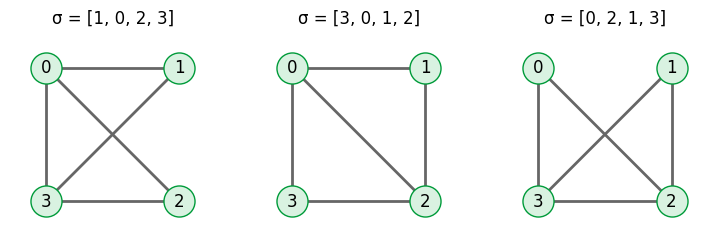

| Permutación (σ)   | ¿Mismo Grafo?   |   Nº Aristas | Espectro Autovalores   | Comportamiento de Grados   |
|:------------------|:----------------|-------------:|:-----------------------|:---------------------------|
| [1, 0, 2, 3]      | Sí              |            5 | Idéntico               | Equivariante               |
| [3, 0, 1, 2]      | Sí              |            5 | Idéntico               | Equivariante               |
| [0, 2, 1, 3]      | Sí              |            5 | Idéntico               | Equivariante               |

In [70]:
# Define tres permutaciones específicas para evaluar de manera práctica en el ejercicio 2
permutaciones = [[1, 0, 2, 3], [3, 0, 1, 2], [0, 2, 1, 3]]

# Prepara los subgráficos horizontales para visualizar el efecto de cada permutación en el cuadrado
fig, axs = plt.subplots(1, 3, figsize=(9, 3))

# Lista para almacenar los resultados del análisis que se presentarán en formato de tabla
datos_tabla = []

for sigma, ax in zip(permutaciones, axs):
    # Obtiene la matriz de permutación P asociada a la permutación actual
    P = matriz_P(sigma)
    # Permuta simétricamente la matriz de adyacencia original para generar el grafo renombrado
    Ap = P@A_A@P.T

    # Dibuja la estructura espacial resultante manteniendo los nodos fijos en las esquinas
    dibujar(nx.from_numpy_array(Ap), pos_esq, ax, f"σ = {sigma}")

    # Verifica las propiedades estructurales de la versión permutada y recopila los datos
    es_isomorfo = nx.is_isomorphic(G, nx.from_numpy_array(Ap))
    num_aristas = Ap.sum() // 2
    mismo_espectro = np.allclose(np.linalg.eigvalsh(Ap), np.linalg.eigvalsh(A_A))
    grados_equivariantes = np.array_equal(Ap.sum(1), P@A_A.sum(1))

    datos_tabla.append([
        str(sigma),
        "Sí" if es_isomorfo else "No",
        num_aristas,
        "Idéntico" if mismo_espectro else "Diferente",
        "Equivariante" if grados_equivariantes else "No equivariante"
    ])

# Muestra los gráficos generados
plt.show()

# Define las cabeceras para la tabla estructurada de resultados
cabeceras = ["Permutación (σ)", "¿Mismo Grafo?", "Nº Aristas", "Espectro Autovalores", "Comportamiento de Grados"]

# Imprime la tabla formateada con la función utilitaria dM_table
dM_table(datos_tabla, cabeceras)

# Nota: Si σ es un automorfismo (por ejemplo [2, 3, 0, 1]), la matriz de adyacencia no cambia.

## 6. La GNN básica (Hamilton §5.1)

Cada capa hace AGGREGATE (sumar los estados de los vecinos) y UPDATE (combinar con el propio estado):
$$\mathbf h_u^{(k)}=\sigma\Big(W_{\text{self}}^{(k)}\mathbf h_u^{(k-1)}+W_{\text{neigh}}^{(k)}\sum_{v\in\mathcal N(u)}\mathbf h_v^{(k-1)}+\mathbf b^{(k)}\Big),$$
y en forma matricial, con los estados como filas de $H$, $H^{(k)}=\sigma\big(AH^{(k-1)}W_{\text{neigh}}+H^{(k-1)}W_{\text{self}}\big)$.

La implementación no usa la matriz $A$ sino la lista de aristas `edge_index`, como en PyG: la fila 0 es el origen del mensaje (el vecino $v$) y la fila 1 el destino ($u$). `index_add_` suma cada mensaje en la fila de su destino.

In [71]:
# Crea el tensor de índices de aristas (edge_index) en formato COO compatible con PyTorch Geometric (PyG).
# La primera dimensión contiene el nodo origen de cada arista de paso de mensajes (vecinos v).
# La segunda dimensión contiene el nodo destino de cada mensaje (nodo objetivo u).
edge_index = torch.tensor([[v for u in lista_A for v in lista_A[u]],     # origen
                           [u for u in lista_A for v in lista_A[u]]])    # destino
print(edge_index)


def capa_gnn(H, edge_index, W_self, W_neigh, b):
    # Divide el tensor de índices en las aristas de origen y destino
    origen, destino = edge_index
    # Paso 1: AGGREGATE (Suma)
    # Inicializa un tensor vacío de mensajes acumulados con las mismas dimensiones que la matriz de atributos H.
    # index_add_ acumula por suma los atributos del nodo 'origen' en la posición correspondiente del nodo 'destino'.
    m = torch.zeros(H.shape[0], H.shape[1]).index_add_(0, destino, H[origen])

    # Paso 2: UPDATE (Combinación y No Linealidad)
    # Realiza la transformación lineal de la auto-información (H @ W_self),
    # la combina con la información agregada del vecindario (m@W_neigh),
    # suma el vector de sesgo (b) y aplica la función de activación tanh.
    return torch.tanh(H@W_self + m@W_neigh + b)

tensor([[1, 3, 0, 2, 3, 1, 3, 0, 1, 2],
        [0, 0, 1, 1, 1, 2, 2, 3, 3, 3]])


Aplicamos una capa con pesos aleatorios a atributos aleatorios y comprobamos que coincide con la forma matricial.

In [72]:
# Establece la semilla de PyTorch para garantizar la reproducibilidad
torch.manual_seed(0)

# Genera atributos iniciales aleatorios H0 para los 4 nodos (cada uno con 3 características)
H0 = torch.randn(4, 3)

# Define de manera aleatoria los pesos de transformación propia (W_self),
# de vecindario (W_neigh) y el vector de sesgo (b)
W_self, W_neigh, b = torch.randn(3, 2), torch.randn(3, 2), torch.randn(2)

# Ejecuta la propagación utilizando nuestra función personalizada basada en edge_index
H1 = capa_gnn(H0, edge_index, W_self, W_neigh, b)

# Convierte la matriz de adyacencia original a un tensor compatible con PyTorch
A_t = torch.tensor(A_A, dtype=torch.float32)

# Compara mediante allclose el resultado obtenido por índices frente al producto formal de matrices
es_igual = torch.allclose(H1, torch.tanh(H0@W_self + A_t@H0@W_neigh + b), atol=1e-6)

# Muestra los resultados utilizando formato Markdown enriquecido
dMarkdown(f"**Matriz de salida de la capa GNN ($H^{(1)}$):**<br>`{H1.tolist()}`")
dMarkdown(f"**¿Es matemáticamente igual al formato matricial?:** `{es_igual}`")


**Matriz de salida de la capa GNN ($H^1$):**<br>`[[-0.903937578201294, -0.9103416800498962], [-0.9796052575111389, -0.9971227645874023], [-0.9880551099777222, -0.9703477621078491], [-0.9999597072601318, -0.9999986290931702]]`

**¿Es matemáticamente igual al formato matricial?:** `True`

**Equivarianza.** Renombramos los nodos con $\sigma$ (intercambiar 2 y 3): los atributos pasan a $PH$ y cada arista $(v,u)$ a $(\sigma(v),\sigma(u))$. La salida de la capa debe ser la misma salida reordenada, $P H^{(1)}$; el MLP de la sección 5 no cumplía nada parecido.

In [73]:
# Convierte la matriz de permutación P23 a un tensor de PyTorch de tipo float32
P_t = torch.tensor(P23, dtype=torch.float32)
# Convierte el vector de permutación de índices sigma23 a un tensor de PyTorch
sig = torch.tensor(sigma23)

# Ejecuta la capa GNN con los atributos de los nodos permutados (P_t @ H0)
# y los índices de aristas actualizados según la permutación sig[edge_index]
H1_B = capa_gnn(P_t@H0, sig[edge_index], W_self, W_neigh, b)

# Verifica mediante allclose la propiedad de equivarianza:
# capa(P * H, σ(aristas)) debe ser igual a aplicar la permutación a la salida original (P * capa(H, aristas))
es_equivariante = torch.allclose(H1_B, P_t@H1, atol=1e-6)

# Muestra el resultado de forma atractiva usando dMarkdown
dMarkdown(f"**¿Se cumple la propiedad de equivarianza capa?:** `{es_equivariante}`")
dMarkdown("($PH, \\sigma(\\text{{aristas}})) = P \\cdot \\text{{capa}}(H, \\text{{aristas}})$")

**¿Se cumple la propiedad de equivarianza capa?:** `True`

($PH, \sigma(\text{{aristas}})) = P \cdot \text{{capa}}(H, \text{{aristas}})$

**La misma capa en PyG.** `MessagePassing` separa los dos pasos: `message` dice qué envía cada vecino $j$ (aquí su estado $\mathbf x_j$), `aggr="add"` los suma y `forward` hace el UPDATE.

In [74]:
from torch_geometric.nn import MessagePassing

class CapaBasica(MessagePassing):
    def __init__(self, W_self, W_neigh, b):
        # Inicializa la clase base especificando que la agregación espacial será la suma (aggr="add")
        super().__init__(aggr="add")              # AGGREGATE = suma
        self.W_self, self.W_neigh, self.b = W_self, W_neigh, b

    def message(self, x_j):                        # mensaje del vecino j: su estado
        # Define el mensaje que envía cada vecino (en este caso, pasa directamente sus características x_j)
        return x_j

    def forward(self, x, edge_index):
        # Propaga los mensajes por el grafo de forma eficiente usando los índices de aristas
        m = self.propagate(edge_index, x=x)        # m_u = suma de x_j sobre los vecinos de u
        # Realiza el paso de UPDATE combinando la auto-información, la vecindad agregada y el sesgo
        return torch.tanh(x@self.W_self + m@self.W_neigh + self.b)   # UPDATE


# Instancia la capa básica de PyG utilizando los pesos y sesgos ya definidos
capa = CapaBasica(W_self, W_neigh, b)

# Verifica si la implementación oficial de PyTorch Geometric coincide con nuestra versión personalizada
coincide = torch.allclose(capa(H0, edge_index), H1, atol=1e-6)

# Muestra el resultado de forma elegante utilizando la función dMarkdown
dMarkdown(f"**¿La implementación de PyG da exactamente el mismo resultado que index_add_?:** `{coincide}`")


**¿La implementación de PyG da exactamente el mismo resultado que index_add_?:** `True`

### Ejercicio 3
Cambie la agregación de suma a **media** (divida la suma por el grado de cada nodo) y compruebe que la capa sigue siendo equivariante. En PyG basta `aggr="mean"`.

In [75]:
def capa_gnn_media(H, edge_index, W_self, W_neigh, b):
    # Divide el tensor de índices en origen y destino de los mensajes
    origen, destino = edge_index

    # Paso 1: AGGREGATE (Suma los atributos de los nodos de origen en el destino)
    suma = torch.zeros(H.shape[0], H.shape[1]).index_add_(0, destino, H[origen])

    # Calcula el grado (número de vecinos) de cada nodo destino
    grado = torch.zeros(H.shape[0]).index_add_(0, destino, torch.ones(destino.shape[0]))

    # Calcula la media dividiendo la suma de los atributos por el grado correspondiente
    m = suma / grado[:, None]

    # Paso 2: UPDATE (Combina la auto-información, el promedio del vecindario y aplica la activación)
    return torch.tanh(H@W_self + m@W_neigh + b)

# Ejecución con los atributos y aristas originales
H1m = capa_gnn_media(H0, edge_index, W_self, W_neigh, b)

# Ejecución aplicando la permutación a los atributos y al orden de los índices
H1m_B = capa_gnn_media(P_t@H0, sig[edge_index], W_self, W_neigh, b)

# Comprobación de la propiedad de equivarianza
es_equivariante = torch.allclose(H1m_B, P_t@H1m, atol=1e-6)

# Presentación del resultado con formato Markdown enriquecido
dMarkdown(f"**¿Es la capa GNN basada en la media equivariante?:** `{es_equivariante}`")

**¿Es la capa GNN basada en la media equivariante?:** `True`

## 7. Normalización: la GCN (Hamilton §5.2)

Con la suma, un nodo de grado alto recibe mensajes más grandes, y al apilar capas los estados crecen como $\lambda_{\max}(A)^k$. La GCN agrega con auto-lazos y normalización simétrica,
$$\hat A=\tilde D^{-1/2}\tilde A\,\tilde D^{-1/2},\qquad \tilde A=A+I,\quad \tilde D=\operatorname{diag}(\tilde A\mathbf 1),$$
cuyos autovalores están en $(-1,1]$.

In [76]:
def gcn_normalizada(A):
    # Añade auto-lazos al grafo sumando la matriz identidad: At = A + I
    At = A + np.eye(len(A))
    # Calcula el grado de cada nodo en la matriz con auto-lazos (suma por filas)
    d = At.sum(1)
    # Aplica la normalización simétrica: At / sqrt(d_i * d_j)
    return At / np.sqrt(np.outer(d, d))

# Obtiene la matriz de adyacencia normalizada para la GCN
A_gcn = gcn_normalizada(A_A)

# Calcula los autovalores de la adyacencia original y de la normalizada para comparar sus rangos espectrales
autovalores_A = np.round(np.linalg.eigvalsh(A_A), 3)
autovalores_gcn = np.round(np.linalg.eigvalsh(A_gcn), 3)

# Formatea la matriz de forma legible para Markdown
matriz_formateada = "\\n".join([str(np.round(fila, 3)) for fila in A_gcn])

# Presenta los resultados usando dMarkdown para una visualización matemática clara y formateada
dMarkdown(f"**Matriz GCN Normalizada** ($\\hat{{A}}$):\\n```\\n{matriz_formateada}\\n```")
dMarkdown(f"**Autovalores de $A$:** `{autovalores_A.tolist()}` (rango sin acotar, propenso a explosión/desvanecimiento)")
dMarkdown(f"**Autovalores de $\\hat{{A}}$:** `{autovalores_gcn.tolist()}` (rango acotado en $(-1, 1]$, ideal para estabilidad numérica)")

**Matriz GCN Normalizada** ($\hat{A}$):\n```\n[0.333 0.289 0.    0.289]\n[0.289 0.25  0.289 0.25 ]\n[0.    0.289 0.333 0.289]\n[0.289 0.25  0.289 0.25 ]\n```

**Autovalores de $A$:** `[-1.562, -1.0, 0.0, 2.562]` (rango sin acotar, propenso a explosión/desvanecimiento)

**Autovalores de $\hat{A}$:** `[-0.167, 0.0, 0.333, 1.0]` (rango acotado en $(-1, 1]$, ideal para estabilidad numérica)

Aplicamos $k$ veces cada matriz a un vector de unos (sin pesos ni no linealidad, para ver solo el efecto de la agregación):

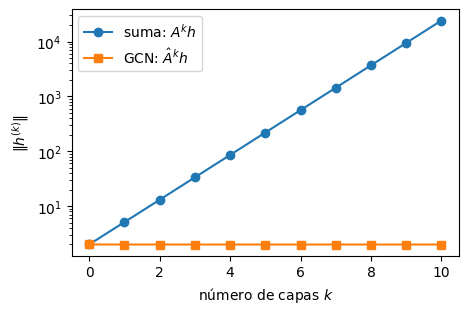

In [77]:
h = np.ones(4)
normas_A = [np.linalg.norm(np.linalg.matrix_power(A_A, k)@h) for k in range(11)]
normas_gcn = [np.linalg.norm(np.linalg.matrix_power(A_gcn, k)@h) for k in range(11)]

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogy(normas_A, "o-", label=r"suma: $A^k h$")
ax.semilogy(normas_gcn, "s-", label=r"GCN: $\hat A^k h$")
ax.set_xlabel("número de capas $k$")
ax.set_ylabel(r"$\|h^{(k)}\|$")
ax.legend()
plt.show()

## Resumen

- Un grafo es su lista de adyacencia; renombrar los nodos ($A\to PAP^\top$) da otra matriz, otra lista ordenada y a veces otra superficie, pero el mismo grafo.
- Un MLP sobre $\mathrm{vec}(A)$ depende de los nombres; las funciones útiles sobre grafos son invariantes o equivariantes.
- La capa de paso de mensajes (AGGREGATE con suma o media, UPDATE) es equivariante por construcción; la GCN normaliza la agregación para que los estados no crezcan.

En la parte 2 apilamos muchas de estas capas, leemos el grafo entero y armamos mini-lotes.